# CardioIA – Ir Além 2: IA em séries temporais de frequência cardíaca

**Pergunta:** para detectar risco cardíaco (taquicardia, bradicardia e crises curtas) em uma janela de frequência cardíaca, como um **classificador tradicional (regressão logística)** se compara a uma **rede neuromórfica simples (neurônios LIF)**?

Roteiro:
1. Gerar uma base sintética e reprodutível de séries de BPM, com variabilidade natural, episódios de risco e **artefatos de sensor**.
2. Treinar a **regressão logística** (com atributos da janela e com a série crua).
3. Montar e "treinar" (busca de hiperparâmetros) uma rede de **2 neurônios LIF**.
4. Comparar desempenho, robustez a artefatos, **latência de detecção online** e custo computacional.

> Contexto: o ESP32 do projeto mede o BPM a cada 2 s e já aplica limites fixos (BPM > 120 ou < 50). Este notebook investiga modelos que aprendem com a série temporal em vez de olhar uma amostra isolada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

SEED = 42
rng = np.random.default_rng(SEED)
N = 60                      # janela de 60 s, 1 amostra por segundo
FIG = Path("../docs/evidencias/ir-alem-2"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

## 1. Base de dados sintética

Não há uma base pública com o formato exato do nosso dispositivo (BPM por segundo, com rótulo de risco). Por isso, a série é **simulada com fisiologia plausível**:

- **Normal:** frequência basal entre 62 e 95 bpm, com arritmia sinusal respiratória (oscilação de 4–6 s) e deriva lenta (passeio aleatório). Um terço das janelas normais tem **esforço físico**, com subida gradual até 100–115 bpm. São "negativos difíceis": perto do limite, mas sem risco.
- **Risco** (rótulo 1), em três tipos:
  - *taquicardia sustentada:* 125–160 bpm;
  - *bradicardia:* 38–48 bpm;
  - *crise paroxística:* de 8 a 20 s a 130–170 bpm no meio de uma janela normal. É o caso mais difícil, porque a média da janela quase não muda.
- **Artefatos em qualquer classe:** em 40 % das janelas, 1 ou 2 picos isolados de +60 a +100 bpm durante 1 s. Isso imita um toque duplo no botão ou o sensor mal posicionado.
- Ruído gaussiano de 2 bpm em todas as amostras.

In [2]:
def normal(n, rng):
    t = np.arange(n)
    rsa = rng.uniform(1, 4) * np.sin(2 * np.pi * t / rng.uniform(4, 6) + rng.uniform(0, 2 * np.pi))
    deriva = np.cumsum(rng.normal(0, 0.6, n)); deriva -= deriva.mean()
    hr = rng.uniform(62, 95) + rsa + deriva
    if rng.random() < 1 / 3:                       # esforço: sobe até 100-115 bpm, sem risco
        alvo = rng.uniform(100, 115)
        hr += np.clip(np.linspace(-1, 1.5, n), 0, 1) * (alvo - hr.mean())
    return hr

def risco(n, rng):
    hr, tipo = normal(n, rng), rng.choice(["taquicardia", "bradicardia", "paroxistica"])
    if tipo == "taquicardia":
        hr = hr - hr.mean() + rng.uniform(125, 160)
    elif tipo == "bradicardia":
        hr = (hr - hr.mean()) * 0.5 + rng.uniform(38, 48)
    else:
        dur = rng.integers(8, 21); ini = rng.integers(5, n - dur)
        hr[ini:ini + dur] = rng.uniform(130, 170) + rng.normal(0, 3, dur)
    return hr, tipo

def artefatos(hr, rng, prob=0.4):
    hr = hr.copy()
    if rng.random() < prob:
        for i in rng.choice(len(hr), rng.integers(1, 3), replace=False):
            hr[i] += rng.uniform(60, 100)
    return hr

def gerar(n_por_classe, rng, prob_artefato=0.4, ruido=2.0):
    X, y, tipos = [], [], []
    for _ in range(n_por_classe):
        X.append(normal(N, rng)); y.append(0); tipos.append("normal")
        h, t = risco(N, rng); X.append(h); y.append(1); tipos.append(t)
    X = np.array([artefatos(x, rng, prob_artefato) + rng.normal(0, ruido, N) for x in X])
    return np.clip(X, 30, 230), np.array(y), np.array(tipos)

X, y, tipos = gerar(1000, rng)
print(X.shape, "| risco:", y.mean().round(2), "|", dict(zip(*np.unique(tipos, return_counts=True))))

(2000, 60) | risco: 0.5 | {np.str_('bradicardia'): np.int64(344), np.str_('normal'): np.int64(1000), np.str_('paroxistica'): np.int64(333), np.str_('taquicardia'): np.int64(323)}


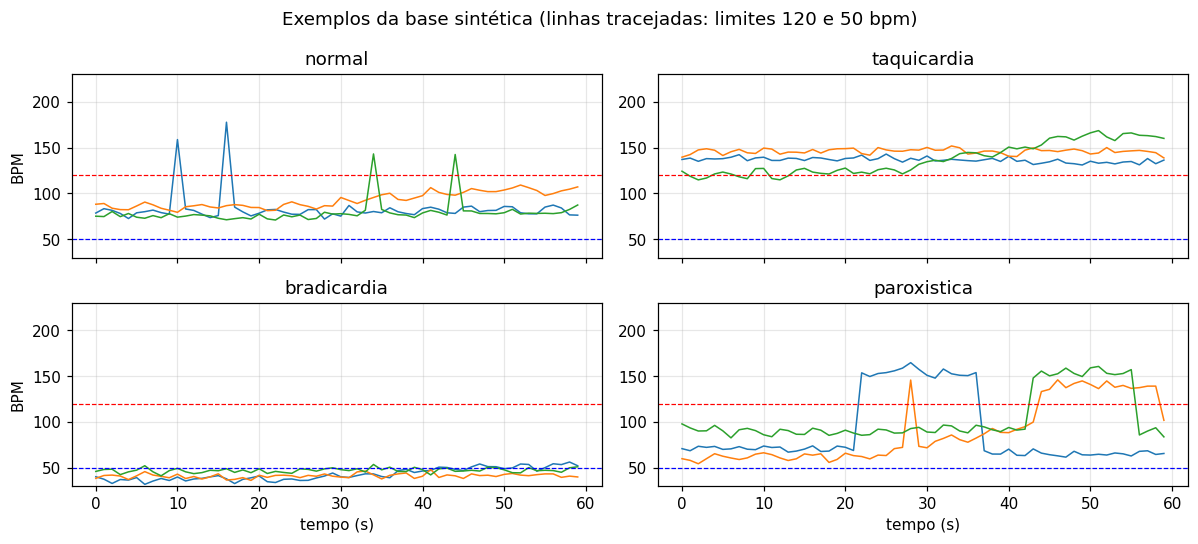

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for ax, tipo in zip(axs.flat, ["normal", "taquicardia", "bradicardia", "paroxistica"]):
    for x in X[tipos == tipo][:3]:
        ax.plot(x, lw=1)
    ax.axhline(120, ls="--", c="r", lw=.8); ax.axhline(50, ls="--", c="b", lw=.8)
    ax.set_title(tipo); ax.set_ylim(30, 230)
for ax in axs[1]: ax.set_xlabel("tempo (s)")
for ax in axs[:, 0]: ax.set_ylabel("BPM")
fig.suptitle("Exemplos da base sintética (linhas tracejadas: limites 120 e 50 bpm)")
fig.tight_layout(); fig.savefig(FIG / "01-exemplos.png")

In [4]:
X_tr, X_te, y_tr, y_te, t_tr, t_te = train_test_split(X, y, tipos, test_size=0.3, stratify=tipos, random_state=SEED)
print(len(X_tr), "treino |", len(X_te), "teste")

1400 treino | 600 teste


## 2. Modelo 1: regressão logística

Três versões, da mais ingênua para a mais informada:

- **LR-crua:** as 60 amostras entram direto, sem engenharia de atributos.
- **LR-estatística:** 8 atributos genéricos de séries temporais: média, desvio-padrão, mínimo, máximo, percentis 10 e 90, RMSSD (variação entre amostras vizinhas) e inclinação.
- **LR-clínica:** atributos com **o mesmo conhecimento de domínio dado ao LIF**: o quanto o BPM passa de 100 e fica abaixo de 60, em média e no pior trecho de 5 s, e a fração do tempo fora da faixa. Esta é a comparação justa com o LIF.

Nas duas, os dados são padronizados (`StandardScaler`) e o modelo é uma `LogisticRegression`.

In [5]:
def atributos(X):
    d = np.diff(X, axis=1)
    inclinacao = np.polyfit(np.arange(X.shape[1]), X.T, 1)[0]
    return np.column_stack([X.mean(1), X.std(1), X.min(1), X.max(1),
                            np.percentile(X, 10, 1), np.percentile(X, 90, 1),
                            np.sqrt((d ** 2).mean(1)), inclinacao])
NOMES = ["média", "desvio", "mínimo", "máximo", "p10", "p90", "RMSSD", "inclinação"]

def atributos_clinicos(X):
    # Mesma codificação de entrada do LIF (seção 3): distância acima de 100 e abaixo de 60 bpm.
    tq, br = np.clip(X - 100, 0, None) / 20, np.clip(60 - X, 0, None) / 10
    pior5 = lambda A: np.lib.stride_tricks.sliding_window_view(A, 5, axis=1).mean(-1).max(1)
    return np.column_stack([tq.mean(1), br.mean(1), pior5(tq), pior5(br), (X > 100).mean(1), (X < 60).mean(1)])
NOMES_CLIN = ["excesso>100 médio", "déficit<60 médio", "excesso>100 pior 5s", "déficit<60 pior 5s", "fração>100", "fração<60"]

lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr_raw = lr().fit(X_tr, y_tr)
lr_est = lr().fit(atributos(X_tr), y_tr)
lr_cli = lr().fit(atributos_clinicos(X_tr), y_tr)

for titulo, modelo, nomes in [("LR-estatística", lr_est, NOMES), ("LR-clínica", lr_cli, NOMES_CLIN)]:
    print(titulo)
    for n, c in sorted(zip(nomes, modelo[-1].coef_[0]), key=lambda p: -abs(p[1])):
        print(f"  {n:>20}: {c:+.2f}")

LR-estatística
                 média: -3.25
                mínimo: +2.41
                   p90: +2.15
                desvio: +1.29
            inclinação: -0.77
                máximo: -0.45
                   p10: -0.36
                 RMSSD: -0.18
LR-clínica
   excesso>100 pior 5s: +4.86
     excesso>100 médio: +3.26
             fração<60: +2.05
      déficit<60 médio: +1.73
    déficit<60 pior 5s: +1.65
            fração>100: +0.11


**Leitura dos coeficientes** (os atributos estão padronizados, então os pesos são comparáveis):

- **LR-estatística:** um modelo linear traça **uma única fronteira** no espaço dos atributos. O risco, porém, é **bimodal**: BPM alto **ou** baixo. Com média e mínimo, a fronteira consegue separar a taquicardia, mas não as duas pontas ao mesmo tempo. É uma relação do tipo "XOR", e o efeito aparece na seção 4.
- **LR-clínica:** os atributos já medem a distância até a faixa normal nas duas direções. Os pesos relevantes ficam todos positivos, e o modelo fica **interpretável** para a equipe médica ("alertou porque passou X% do tempo acima de 100 bpm").

## 3. Modelo 2: rede neuromórfica com neurônios LIF

O neurônio **Leaky Integrate-and-Fire** acumula a corrente de entrada no potencial de membrana $V$, que "vaza" com constante de tempo $\tau$:

$$\tau \frac{dV}{dt} = -V + I(t), \qquad V \ge V_{th} \Rightarrow \text{spike e } V \leftarrow 0$$

A rede tem **2 neurônios**, um para cada tipo de risco. A entrada de cada um é a distância do BPM até a faixa normal (codificação por corrente):

- neurônio **taqui:** $I = g\,\max(0,\ \text{BPM} - 100)/20$
- neurônio **bradi:** $I = g\,\max(0,\ 60 - \text{BPM})/10$

Com $V_{th}=1$, o vazamento faz o neurônio "esquecer" estímulos antigos. Quanto mais longe da faixa normal e por mais tempo o BPM ficar, mais spikes ele gera. A decisão é **"risco" se a rede emitir pelo menos k spikes**. A combinação de $\tau$, $g$ e $k$ define o equilíbrio entre detectar rápido e ignorar picos isolados (seção 5).

**Treino:** a rede não usa gradiente. É uma busca em grade de $\tau$, $g$ e $k$ que maximiza o F1 no conjunto de treino (3 hiperparâmetros, contra 9 pesos da LR-atributos e 61 da LR-crua).

In [6]:
def lif(X, tau, g, dt=1.0, vth=1.0):
    # Simula os 2 neurônios em todas as janelas de uma vez. Devolve spikes [janela, tempo, neurônio].
    X = np.atleast_2d(X)
    I = np.stack([g * np.clip(X - 100, 0, None) / 20, g * np.clip(60 - X, 0, None) / 10], axis=-1)
    V = np.zeros((X.shape[0], 2)); S = np.zeros_like(I)
    for t in range(X.shape[1]):
        V += dt / tau * (-V + I[:, t])
        S[:, t] = V >= vth
        V[S[:, t] == 1] = 0.0
    return S

def lif_prever(X, tau, g, k):
    spikes = lif(X, tau, g).sum(axis=(1, 2))
    return (spikes >= k).astype(int), spikes

grade = [(tau, g, k) for tau in (2, 4, 8, 16) for g in (1, 2, 3, 4) for k in (1, 2, 3, 5, 8)]
f1s = [f1_score(y_tr, lif_prever(X_tr, *p)[0]) for p in grade]
TAU, G, K = grade[int(np.argmax(f1s))]
print(f"melhor: tau={TAU} s, g={G}, k={K} spikes | F1 treino = {max(f1s):.3f}")

melhor: tau=2 s, g=1, k=3 spikes | F1 treino = 0.999


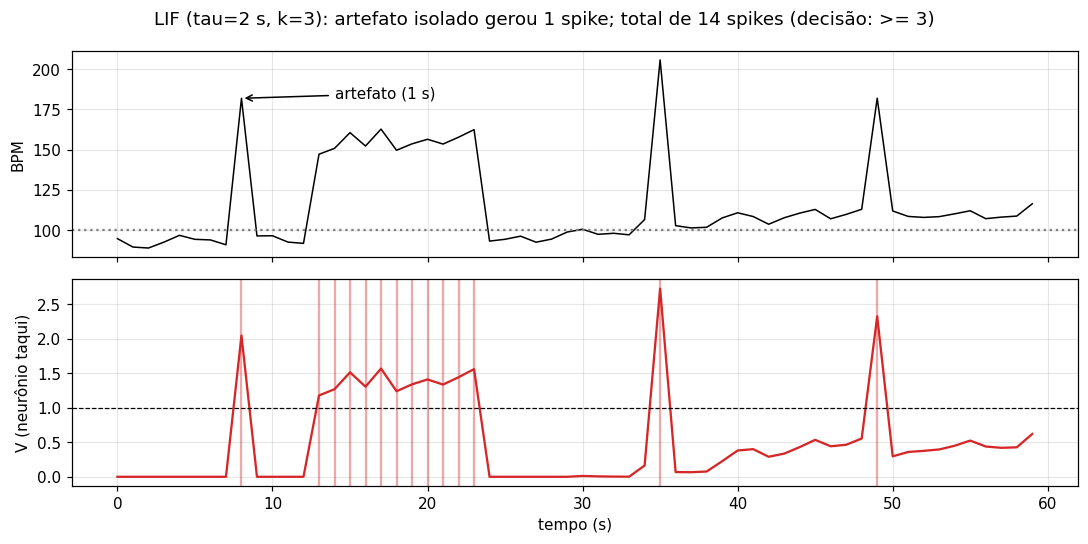

In [7]:
# Como a rede "vê" uma crise paroxística com artefato
i = np.where((t_te == "paroxistica"))[0][0]
x = X_te[i].copy(); x[8] += 90                           # artefato extra só para ilustrar
I_tq = G * np.clip(x - 100, 0, None) / 20
V, Vs, sp = 0.0, [], []
for t in range(N):
    V += 1 / TAU * (-V + I_tq[t]); Vs.append(V)
    if V >= 1: sp.append(t); V = 0.0
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a1.plot(x, c="k", lw=1); a1.axhline(100, ls=":", c="gray"); a1.set_ylabel("BPM")
a1.annotate("artefato (1 s)", (8, x[8]), xytext=(14, x[8]), arrowprops=dict(arrowstyle="->"))
a2.plot(Vs, c="tab:red"); a2.axhline(1, ls="--", c="k", lw=.8); a2.set_ylabel("V (neurônio taqui)")
for s in sp: a2.axvline(s, c="tab:red", alpha=.4)
a2.set_xlabel("tempo (s)")
art = "gerou 1 spike" if any(s in (8, 9) for s in sp) else "não atingiu o limiar"
fig.suptitle(f"LIF (tau={TAU} s, k={K}): artefato isolado {art}; total de {len(sp)} spikes (decisão: >= {K})")
fig.tight_layout(); fig.savefig(FIG / "02-lif-membrana.png")

## 4. Resultados no conjunto de teste

In [8]:
# Cada modelo: função que devolve (decisão 0/1, score contínuo) para um lote de janelas
def _lr(modelo, feats):
    return lambda X: (lambda p: ((p > .5).astype(int), p))(modelo.predict_proba(feats(X))[:, 1])

PREVER = {
    "LR-crua": _lr(lr_raw, lambda X: X),
    "LR-estatística": _lr(lr_est, atributos),
    "LR-clínica": _lr(lr_cli, atributos_clinicos),
    "LIF": lambda X: lif_prever(X, TAU, G, K),
}
modelos = {n: f(X_te) for n, f in PREVER.items()}
print(f"{'modelo':<18}{'acurácia':>9}{'precisão':>9}{'recall':>8}{'F1':>7}{'AUC':>7}")
for nome, (pred, score) in modelos.items():
    print(f"{nome:<18}{accuracy_score(y_te, pred):>9.3f}{precision_score(y_te, pred):>9.3f}"
          f"{recall_score(y_te, pred):>8.3f}{f1_score(y_te, pred):>7.3f}{roc_auc_score(y_te, score):>7.3f}")

modelo             acurácia precisão  recall     F1    AUC
LR-crua               0.673    0.728   0.553  0.629  0.675
LR-estatística        0.760    0.911   0.577  0.706  0.673
LR-clínica            0.985    0.997   0.973  0.985  1.000
LIF                   1.000    1.000   1.000  1.000  1.000


In [9]:
print("Recall (acerto) por tipo de janela; para 'normal' é a taxa de verdadeiro negativo:\n")
print(f"{'tipo':<13}" + "".join(f"{n:>16}" for n in modelos))
for tipo in ["normal", "taquicardia", "bradicardia", "paroxistica"]:
    m = t_te == tipo
    alvo = 0 if tipo == "normal" else 1
    print(f"{tipo:<13}" + "".join(f"{(pred[m] == alvo).mean():>16.3f}" for pred, _ in modelos.values()))

Recall (acerto) por tipo de janela; para 'normal' é a taxa de verdadeiro negativo:

tipo                  LR-crua  LR-estatística      LR-clínica             LIF
normal                  0.793           0.943           0.997           1.000
taquicardia             0.670           0.763           1.000           1.000
bradicardia             0.097           0.000           1.000           1.000
paroxistica             0.910           0.990           0.920           1.000


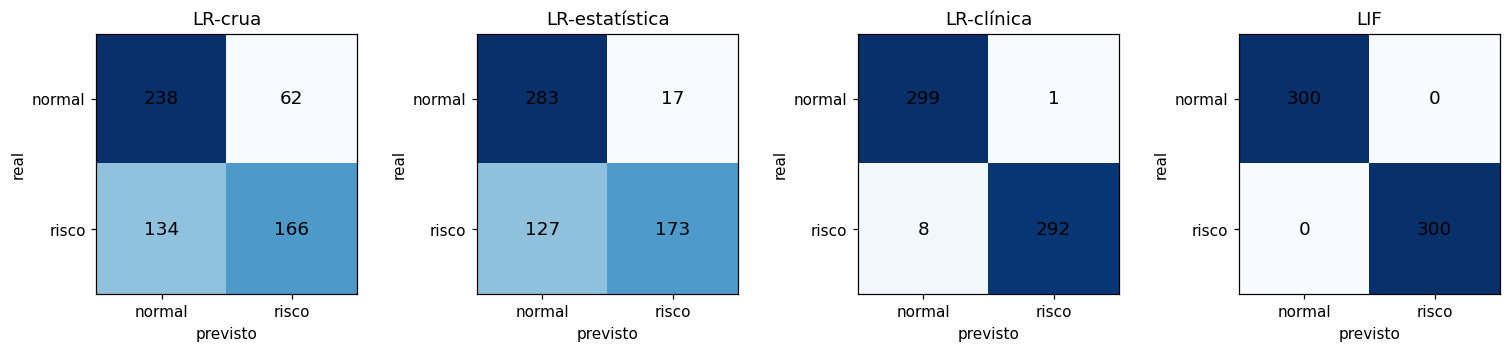

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (nome, (pred, _)) in zip(axs, modelos.items()):
    cm = confusion_matrix(y_te, pred)
    ax.imshow(cm, cmap="Blues"); ax.set_title(nome); ax.grid(False)
    for (r, c), v in np.ndenumerate(cm): ax.text(c, r, v, ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["normal", "risco"]); ax.set_yticks([0, 1], ["normal", "risco"])
    ax.set_xlabel("previsto"); ax.set_ylabel("real")
fig.tight_layout(); fig.savefig(FIG / "03-confusao.png")

## 5. Robustez a artefatos

O sensor real gera picos espúrios (toque duplo no botão, dedo mal posicionado no sensor óptico). Aqui os modelos **já treinados** são avaliados em bases novas, com a probabilidade de artefato variando de 0 a 100 % e com mais picos por janela.

In [11]:
def artefatos_fortes(hr, rng, prob):
    hr = hr.copy()
    if rng.random() < prob:
        for i in rng.choice(len(hr), rng.integers(2, 5), replace=False):
            hr[i] += rng.uniform(60, 100)
    return hr

PROBS = [0, .25, .5, .75, 1.0]

def robustez(prever):
    res = {n: [] for n in prever}
    for p in PROBS:
        r = np.random.default_rng(7)                      # mesma base para todos os modelos
        Xr, yr = [], []
        for _ in range(400):
            Xr.append(normal(N, r)); yr.append(0)
            Xr.append(risco(N, r)[0]); yr.append(1)
        Xr = np.clip(np.array([artefatos_fortes(x, r, p) + r.normal(0, 2, N) for x in Xr]), 30, 230)
        for n, f in prever.items():
            res[n].append(f1_score(yr, f(Xr)[0]))
    return res

res = robustez(PREVER)
print(f"{'fração com artefatos:':<22}" + " ".join(f"{p:>6.2f}" for p in PROBS))
for n, v in res.items(): print(f"{n:<22}" + " ".join(f"{x:>6.3f}" for x in v))

fração com artefatos:   0.00   0.25   0.50   0.75   1.00
LR-crua                0.692  0.670  0.650  0.617  0.622
LR-estatística         0.772  0.733  0.722  0.694  0.668
LR-clínica             0.994  0.983  0.981  0.975  0.978
LIF                    1.000  0.931  0.890  0.833  0.779


### 5.1 Re-treino com aumento de dados (artefatos fortes)

Os hiperparâmetros do LIF foram escolhidos numa base com artefatos leves, e por isso a busca preferiu um $\tau$ curto. Com $\tau$ curto, cada pico isolado gera um spike, e 3 ou 4 picos já passam do limite $k$. Para corrigir, **os dois modelos são re-treinados** com o treino original mais uma cópia contaminada por artefatos fortes. A base de teste da curva de robustez continua sendo a mesma.

LIF-robusto: tau=4 s, g=3, k=8 (antes: tau=2, g=1, k=3)


LR-clínica (aum.)  teste original: F1=0.974  AUC=1.000
LIF (aum.)         teste original: F1=0.998  AUC=1.000

LR-crua                0.692  0.670  0.650  0.617  0.622
LR-estatística         0.772  0.733  0.722  0.694  0.668
LR-clínica             0.994  0.983  0.981  0.975  0.978
LIF                    1.000  0.931  0.890  0.833  0.779
LR-clínica (aum.)      0.973  0.975  0.976  0.983  0.988
LIF (aum.)             0.996  0.993  0.982  0.980  0.965


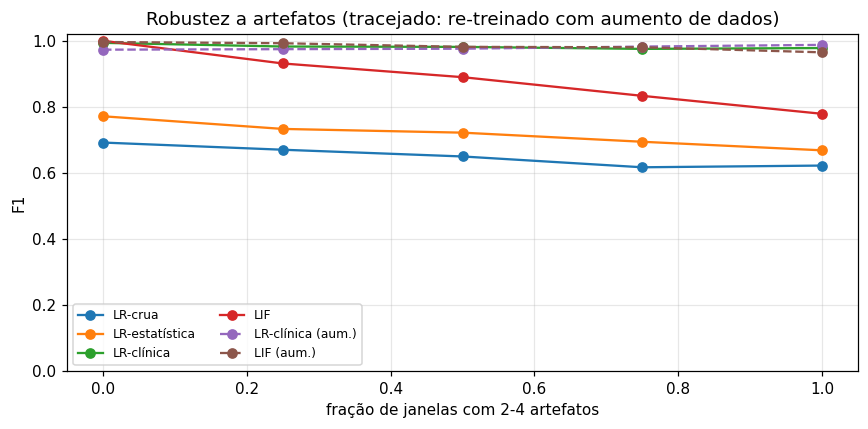

In [12]:
r = np.random.default_rng(99)
X_aug = np.vstack([X_tr, np.clip(np.array([artefatos_fortes(x, r, .5) for x in X_tr]), 30, 230)])
y_aug = np.concatenate([y_tr, y_tr])

f1s_aug = [f1_score(y_aug, lif_prever(X_aug, *p)[0]) for p in grade]
TAU_R, G_R, K_R = grade[int(np.argmax(f1s_aug))]
lr_cli_r = lr().fit(atributos_clinicos(X_aug), y_aug)
print(f"LIF-robusto: tau={TAU_R} s, g={G_R}, k={K_R} (antes: tau={TAU}, g={G}, k={K})")

ROBUSTOS = {"LR-clínica (aum.)": _lr(lr_cli_r, atributos_clinicos), "LIF (aum.)": lambda X: lif_prever(X, TAU_R, G_R, K_R)}
res.update(robustez(ROBUSTOS))
for n, f in ROBUSTOS.items():
    pred, s = f(X_te)
    print(f"{n:<18} teste original: F1={f1_score(y_te, pred):.3f}  AUC={roc_auc_score(y_te, s):.3f}")
print()
for n, v in res.items(): print(f"{n:<22}" + " ".join(f"{x:>6.3f}" for x in v))

fig, ax = plt.subplots(figsize=(8, 4))
for n, v in res.items():
    ax.plot(PROBS, v, "o--" if "aum." in n else "o-", label=n)
ax.set_xlabel("fração de janelas com 2-4 artefatos"); ax.set_ylabel("F1"); ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, ncol=2); ax.set_title("Robustez a artefatos (tracejado: re-treinado com aumento de dados)")
fig.tight_layout(); fig.savefig(FIG / "04-robustez.png")

## 6. Latência de detecção online

No dispositivo, o que importa é **quanto tempo depois do início da crise o alerta sai**. Para medir isso, são simulados fluxos de 120 s: 60 s normais e, a partir de t = 60 s, uma taquicardia de 30 s.

- A **LR** precisa de uma janela completa. Ela é aplicada a cada segundo sobre os últimos 60 s (janela deslizante).
- O **LIF** processa amostra por amostra, com estado próprio, e alerta quando atinge k spikes **acumulados desde o início da crise**. Na prática, a contagem é feita numa janela deslizante de 60 s, igual à da LR.

LR-estatística   mediana = 6 s | p90 = 6 s | não detectou: 0%
LR-clínica       mediana = 4 s | p90 = 18 s | não detectou: 0%
LIF              mediana = 3 s | p90 = 5 s | não detectou: 0%
LIF (aum.)       mediana = 7 s | p90 = 9 s | não detectou: 0%


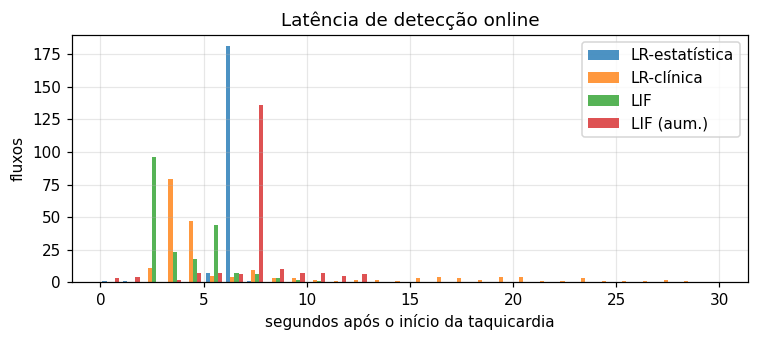

In [13]:
def latencias(n_fluxos=200, seed=11):
    r = np.random.default_rng(seed)
    lat = {"LR-estatística": [], "LR-clínica": [], "LIF": [], "LIF (aum.)": []}
    for _ in range(n_fluxos):
        fluxo = np.concatenate([normal(60, r), normal(60, r)])
        fluxo[60:90] = r.uniform(125, 160) + r.normal(0, 3, 30)
        fluxo = fluxo + r.normal(0, 2, 120)
        janelas = np.lib.stride_tricks.sliding_window_view(fluxo, N)[1:]      # janela que termina em t=60..119
        for n in ("LR-estatística", "LR-clínica"):
            p = PREVER[n](janelas)[0]
            lat[n].append(np.argmax(p) if p.any() else np.nan)
        for n, (tau, g, k) in {"LIF": (TAU, G, K), "LIF (aum.)": (TAU_R, G_R, K_R)}.items():
            spk = lif(fluxo[None], tau, g)[0].sum(1)                          # spikes por segundo
            acum = np.convolve(spk, np.ones(N), mode="full")[:120]            # spikes nos últimos 60 s
            det = np.where(acum[60:] >= k)[0]
            lat[n].append(det[0] if len(det) else np.nan)
    return {k: np.array(v, float) for k, v in lat.items()}

lat = latencias()
for n, v in lat.items():
    ok = v[~np.isnan(v)]
    med = f"{np.median(ok):.0f} s | p90 = {np.percentile(ok, 90):.0f} s" if len(ok) else "-"
    print(f"{n:<16} mediana = {med} | não detectou: {np.isnan(v).mean():.0%}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([v[~np.isnan(v)] for v in lat.values()], bins=range(0, 31), label=list(lat), alpha=.8)
ax.set_xlabel("segundos após o início da taquicardia"); ax.set_ylabel("fluxos"); ax.legend()
ax.set_title("Latência de detecção online"); fig.tight_layout(); fig.savefig(FIG / "05-latencia.png")

## 7. Custo computacional (por segundo de sinal, no dispositivo)

| | LR-crua | LR-estatística | LR-clínica | LIF |
|---|---|---|---|---|
| Parâmetros treináveis | 61 pesos | 9 pesos | 7 pesos | 3 hiperparâmetros |
| Memória de estado | janela de 60 amostras | janela de 60 amostras | janela de 60 amostras | 2 potenciais (2 floats) |
| Operações por nova amostra* | ~120 | ~600 | ~700 | ~10 |
| Saída | probabilidade | probabilidade | probabilidade | contagem de spikes |

\* Estimativa com janela deslizante, refazendo o cálculo a cada segundo. O LIF é **orientado a eventos**: quando o BPM está na faixa normal, a corrente de entrada é zero e quase não há trabalho. Esse é o argumento central do hardware neuromórfico (Loihi, SpiNNaker) para vestíveis com bateria.

In [14]:
resumo = {n: dict(F1=f1_score(y_te, pred), AUC=roc_auc_score(y_te, s)) for n, (pred, s) in modelos.items()}
for n, m in resumo.items(): print(f"{n:<18} F1={m['F1']:.3f}  AUC={m['AUC']:.3f}")
print(f"\nLIF escolhido: tau={TAU} s, g={G}, k={K}")

LR-crua            F1=0.629  AUC=0.675
LR-estatística     F1=0.706  AUC=0.673
LR-clínica         F1=0.985  AUC=1.000
LIF                F1=1.000  AUC=1.000

LIF escolhido: tau=2 s, g=1, k=3


## 8. Conclusões

Resumo dos números desta execução (semente 42):

| Modelo | F1 teste | F1 com artefatos em 100 % das janelas | Latência mediana / p90 |
|---|---|---|---|
| LR-crua | 0,63 | 0,62 | – |
| LR-estatística | 0,71 | 0,67 | 6 s / 6 s |
| LR-clínica | 0,985 | 0,98 | 4 s / 18 s |
| LIF (τ = 2 s, k = 3) | 1,00 | 0,78 | 3 s / 5 s |
| LIF re-treinado (τ = 4 s, k = 8) | 0,998 | 0,965 | 7 s / 9 s |

1. **Representação importa mais que o modelo.** Com atributos genéricos (LR-crua e LR-estatística), a regressão logística não detecta a bradicardia: o acerto fica entre 0 e 10 %. O risco é bimodal, alto **ou** baixo, e uma única fronteira linear não cobre as duas pontas. Quando recebe a mesma codificação clínica do LIF (distância até 100 e 60 bpm), a LR sobe para F1 = 0,985. O mérito principal está no conhecimento de domínio embutido na entrada.
2. **Na base limpa, o LIF empata ou vence.** Ele acerta 100 % das crises paroxísticas, contra 92 % da LR-clínica, porque integra o sinal no tempo em vez de resumir a janela.
3. **Robustez × latência é o verdadeiro dilema.** O LIF com τ curto alerta mais rápido (mediana de 3 s), mas com muitos artefatos gera falsos alarmes (F1 cai para 0,78). Re-treinado com aumento de dados, ele escolheu τ maior e k maior: fica robusto (0,965), mas passa a precisar de 7 s para alertar. A LR-clínica é robusta, porque usa médias, porém tem cauda longa de latência (p90 = 18 s): em parte das crises, só alerta quando elas já ocupam boa parte da janela. **O ajuste de τ e k funciona como um "botão" clínico explícito entre sensibilidade e falsos alarmes.**
4. **Custo:** o LIF tem 2 estados e cerca de 10 operações por amostra, contra uma janela de 60 amostras e centenas de operações da LR. Ele caberia **dentro do firmware do ESP32**, no lugar do limite fixo atual, e é orientado a eventos: com o BPM na faixa normal, a entrada é zero.
5. **Limitações do LIF:**
   - A saída é uma contagem de spikes, não uma probabilidade calibrada. A LR entrega probabilidade e pesos explicáveis.
   - O "treino" é uma busca em grade, que não escala para redes grandes. Elas exigiriam *surrogate gradients* (snnTorch, Norse).
6. **Limitações do estudo:**
   - A base é sintética, e o 100 % do LIF reflete isso, porque as classes são bem separadas. Com dados reais, os números devem cair.
   - O próximo passo é validar com séries do PhysioNet (MIT-BIH, *Normal Sinus Rhythm*) e com as leituras do próprio ESP32 da bancada, e incluir ritmos irregulares (fibrilação atrial), em que o BPM médio é normal.

**Recomendação para o CardioIA:**
- **LIF (com aumento de dados) no Edge:** alerta local barato e robusto, com o equilíbrio ajustável por τ e k.
- **LR-clínica no Fog/Cloud (API do Ir Além 1):** probabilidade calibrada e explicação por atributo para a equipe médica.